# Checking the Run Logs

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt

# indices in the particles array 
# boundary values
# semi major axis a
a_min = 1.8
a_max = 3.95
# eccentricity e
e_min = 0.0
e_max = 0.34
# inclination i
i_min = 0.0
i_max = 0.55

A = 6
E = 7
I = 8

ind_limits = {A: (a_min, a_max), E: (e_min, e_max), I: (i_min, i_max)}


In [2]:
particles_assigned = pd.read_hdf('../../asteroid_data/sim_data/mvc_3/inputs/clone_assignments.h5')

particles_assigned

,ast_name,particle_types,sim_no,particle_number
0,1303,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]",0,10
1,1303,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcm]",1,10
2,1303,"[Xcp, Ycp, Zcp, VXcp, VYcm, VZcp]",2,10
3,1303,"[Xcp, Ycp, Zcp, VXcp, VYcm, VZcm]",3,10
4,1303,"[Xcp, Ycp, Zcp, VXcm, VYcp, VZcp]",4,10
...,...,...,...,...
57130,P_426,"[Xcm, Ycm, Zcm, VXcm, VYcp, VZcp]",19040,12
57131,P_426,"[Xcm, Ycm, Zcm, VXcm, VYcp, VZcm]",19041,12
57132,P_426,"[Xcm, Ycm, Zcm, VXcm, VYcm, VZcp]",19042,12
57133,P_426,"[Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]",19043,12


In [5]:
run_log = h5.File('../../asteroid_data/sim_data/mvc_3/results/pvals_00000.h5',"r")

int_values = run_log['integration_time_values'][()]
sim_energy_values = run_log['sim_energy_values'][()]
part_values = run_log['particle_values'][()]

In [8]:
print(f"Sim number:{run_log.attrs['simulation']} Years modelled:{run_log.attrs['int_length']:0.1e} Walltime:{datetime.timedelta(seconds=run_log.attrs['clock_time'])}")

sim_no = int(run_log.attrs['simulation'])

sim_particles = particles_assigned[particles_assigned['sim_no']==sim_no]
sim_particles

Sim number:00000 Years modelled:1.0e+07 Walltime:0:33:05.154965


,ast_name,particle_types,sim_no,particle_number
0,1303,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]",0,10
19045,493333,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]",0,11
38090,2001 QO310,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]",0,12


In [9]:
outside = np.where(((part_values[:,:,A] > a_max) | (part_values[:,:,A] < a_min)))
print(len(outside[0]))
print(int_values[np.min(outside[0])]/(2*np.pi))
print(np.unique(outside[1]))

for p_num in np.unique(outside[1]):
    print(sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].tolist())
    p, n = sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].array[0]
    print(p, ''.join(n))


0


ValueError: zero-size array to reduction operation minimum which has no identity

In [10]:
part_values[:,6:]

array([], shape=(10000, 0, 11), dtype=float64)

In [13]:
part_values[:,:,6]

array([[3.2157089 , 3.20274481, 2.69603548],
       [3.21333863, 3.19711861, 2.67723445],
       [3.20516141, 3.19364066, 2.69877954],
       ...,
       [3.23733882, 3.20652071, 2.67768525],
       [3.19944977, 3.2090822 , 2.68549056],
       [3.20234766, 3.2361149 , 2.66441988]])

In [14]:
s0003_z = scipy.stats.zscore(part_values[:,:,6:],0)

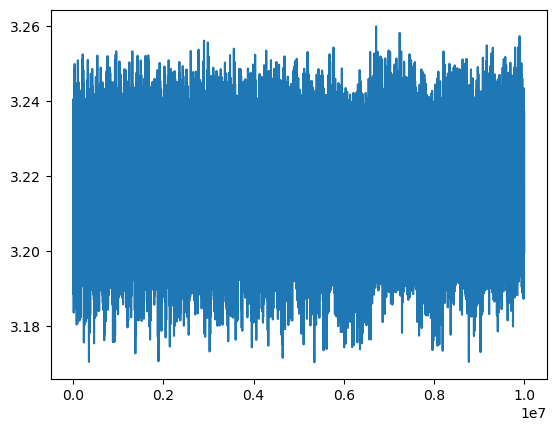

In [15]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,6])

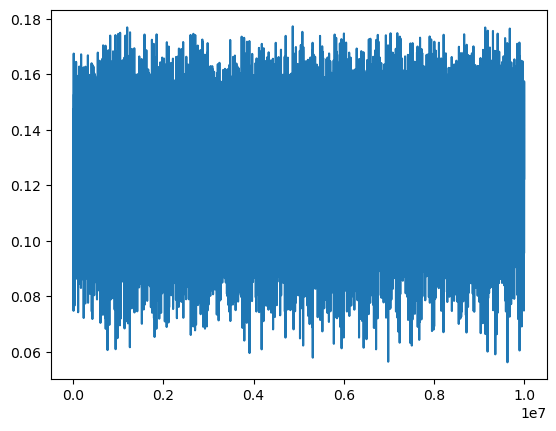

In [16]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,7])

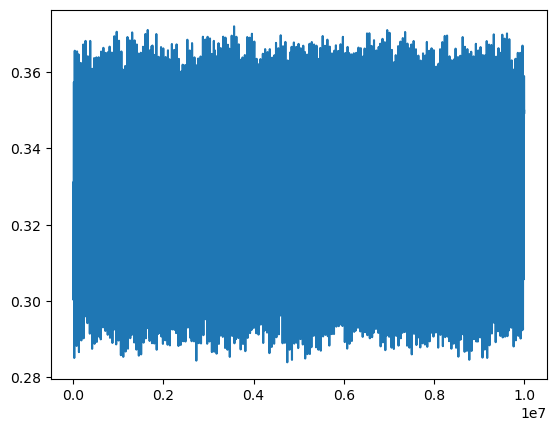

In [17]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,8])

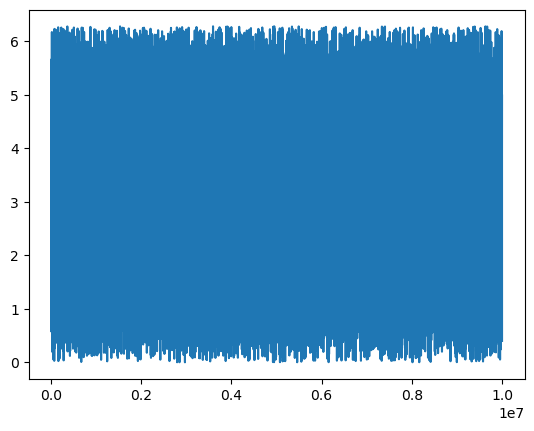

In [18]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,9])

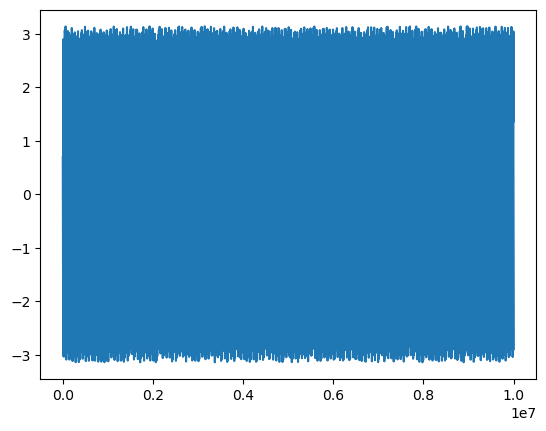

In [19]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,10])

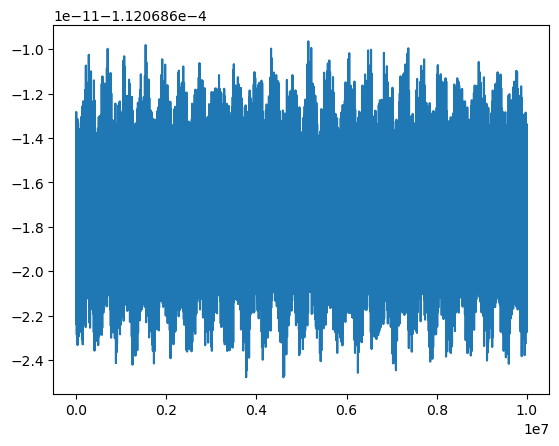

In [20]:
plt.plot(int_values[:]/(2*np.pi), sim_energy_values)

In [26]:
os_run_log = h5.File('../../asteroid_data/sim_data/mvc_3/results/pvals_actives.h5',"r")

ts_run_log = h5.File('../../asteroid_data/sim_data/mvc_3/check_files/pvals_actives.h5',"r")

one_iv = os_run_log['integration_time_values'][()]
one_sev = os_run_log['sim_energy_values'][()]
one_pv = os_run_log['particle_values'][()]

#os_run_log.close()

two_iv = ts_run_log['integration_time_values'][()]
two_sev = ts_run_log['sim_energy_values'][()]
two_pv = ts_run_log['particle_values'][()]

#ts_run_log.close()

In [27]:
np.any(one_pv != two_pv)

True

In [32]:
two_iv[:]/(2*np.pi)

array([1.59154943e+01, 1.02585574e+03, 2.03579599e+03, 3.04573624e+03,
       4.05567648e+03, 5.06561673e+03, 6.07555698e+03, 7.08549723e+03,
       8.09543747e+03, 9.10537772e+03, 1.01153180e+04, 1.11252582e+04,
       1.21351985e+04, 1.31451387e+04, 1.41550790e+04, 1.51650192e+04,
       1.61749595e+04, 1.71848997e+04, 1.81948399e+04, 1.92047802e+04,
       2.02147204e+04, 2.12246607e+04, 2.22346009e+04, 2.32445412e+04,
       2.42544814e+04, 2.52644217e+04, 2.62743619e+04, 2.72843022e+04,
       2.82942424e+04, 2.93041827e+04, 3.03141229e+04, 3.13240632e+04,
       3.23340034e+04, 3.33439437e+04, 3.43538839e+04, 3.53638242e+04,
       3.63737644e+04, 3.73837047e+04, 3.83936449e+04, 3.94035851e+04,
       4.04135254e+04, 4.14234656e+04, 4.24334059e+04, 4.34433461e+04,
       4.44532864e+04, 4.54632266e+04, 4.64731669e+04, 4.74831071e+04,
       4.84930474e+04, 4.95029876e+04, 5.05129279e+04, 5.15228681e+04,
       5.25328084e+04, 5.35427486e+04, 5.45526889e+04, 5.55626291e+04,
      

In [28]:
ts_run_log = h5.File('../../asteroid_data/sim_data/mvc_3/check_files/pvals_actives.h5',"r")


In [29]:
ts_run_log.attrs['start_index']

0